In [10]:
ls

Threshold Analyser.ipynb
threshold_curves.png
validation_eval_service_10/
validation_eval_service_3/
validation_eval_service_5/
validation_eval_service_8/
zscore_margin_calibration_BAAI_bge-large-en-v1.5.csv
zscore_margin_calibration_Qwen_Qwen3-Reranker-4B.csv


In [11]:
import os
import json
import pandas as pd


pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)

In [19]:
base_path = "../results_auto_threshold"


df = pd.read_csv(
    f"{base_path}/zscore_margin_calibration_Qwen_Qwen3-Reranker-4B.csv"
)


In [20]:
df[df["k"] == 10]

,router,model_name,k,threshold,accuracy,fallback_rate,specialist_recall,general_recall,balanced_accuracy,recall_gap
63,cross-encoder,Qwen/Qwen3-Reranker-4B,10,0,0.6915,0.0000,0.9205,0.00,0.4603,0.9205
64,cross-encoder,Qwen/Qwen3-Reranker-4B,10,5,0.6915,0.0000,0.9205,0.00,0.4603,0.9205
65,cross-encoder,Qwen/Qwen3-Reranker-4B,10,10,0.6915,0.0000,0.9205,0.00,0.4603,0.9205
66,cross-encoder,Qwen/Qwen3-Reranker-4B,10,15,0.6915,0.0000,0.9205,0.00,0.4603,0.9205
67,cross-encoder,Qwen/Qwen3-Reranker-4B,10,20,0.6915,0.0000,0.9205,0.00,0.4603,0.9205
68,cross-encoder,Qwen/Qwen3-Reranker-4B,10,25,0.6915,0.0000,0.9205,0.00,0.4603,0.9205
69,cross-encoder,Qwen/Qwen3-Reranker-4B,10,30,0.6915,0.0000,0.9205,0.00,0.4603,0.9205
70,cross-encoder,Qwen/Qwen3-Reranker-4B,10,35,0.6915,0.0000,0.9205,0.00,0.4603,0.9205
71,cross-encoder,Qwen/Qwen3-Reranker-4B,10,40,0.7114,0.0249,0.9205,0.08,0.5003,0.8405
72,cross-encoder,Qwen/Qwen3-Reranker-4B,10,45,0.7264,0.0398,0.9205,0.14,0.5303,0.7805


In [4]:
# df[df["k"]== 3].sort_values(by="accuracy", ascending=False)

In [5]:
best_per_k = df.loc[
    df.groupby("k")["accuracy"].idxmax()
][[
    "k",
    "threshold",
    "accuracy",
    "general_recall",
    "specialist_recall",
    "fallback_rate"
]]

best_per_k

,k,threshold,accuracy,general_recall,specialist_recall,fallback_rate
11,3,1.8,0.8681,0.84,0.9024,0.5055
25,5,1.6,0.8938,0.88,0.9048,0.4425
35,8,1.0,0.8571,0.82,0.8729,0.3095
54,10,1.3,0.8557,0.94,0.8278,0.3433


In [6]:
global_threshold = (
    df[df["k"] >= 5]
#     df
    .groupby("threshold")[
        [
            "accuracy",
            "general_recall",
            "specialist_recall",
            "fallback_rate",
        ]
    ]
    .mean()
    .round(4)
)

In [7]:
global_threshold.sort_values(by="accuracy", ascending=False)

,accuracy,general_recall,specialist_recall,fallback_rate
threshold,,,,
1.50,0.8620,0.9400,0.8364,0.4038
1.30,0.8600,0.8800,0.8649,0.3613
1.40,0.8570,0.9067,0.8437,0.3853
1.60,0.8546,0.9600,0.8169,0.4270
1.20,0.8514,0.8467,0.8702,0.3468
1.00,0.8479,0.7733,0.8954,0.3052
1.10,0.8439,0.8067,0.8781,0.3280
1.70,0.8420,0.9667,0.7943,0.4475
1.80,0.8289,0.9733,0.7699,0.4699


,Model,Intercept,Scale / slope,SSE,R²
0,Affine: a+b·ln(√(k−1)),109.5723,-46.0546,10.05,0.986


,k value,threshold,Affine: a+b·ln(√(k−1))
0,10,60.00,58.98
1,5,75.00,77.65
2,8,65.00,64.76
3,3,95.00,93.61


,k (curve),Affine: a+b·ln(√(k−1))
0,3.00,93.61
1,3.25,90.90
2,3.50,88.47
3,3.75,86.28
4,4.00,84.27
5,4.25,82.43
6,4.50,80.72
7,4.75,79.14
8,5.00,77.65
9,5.25,76.25


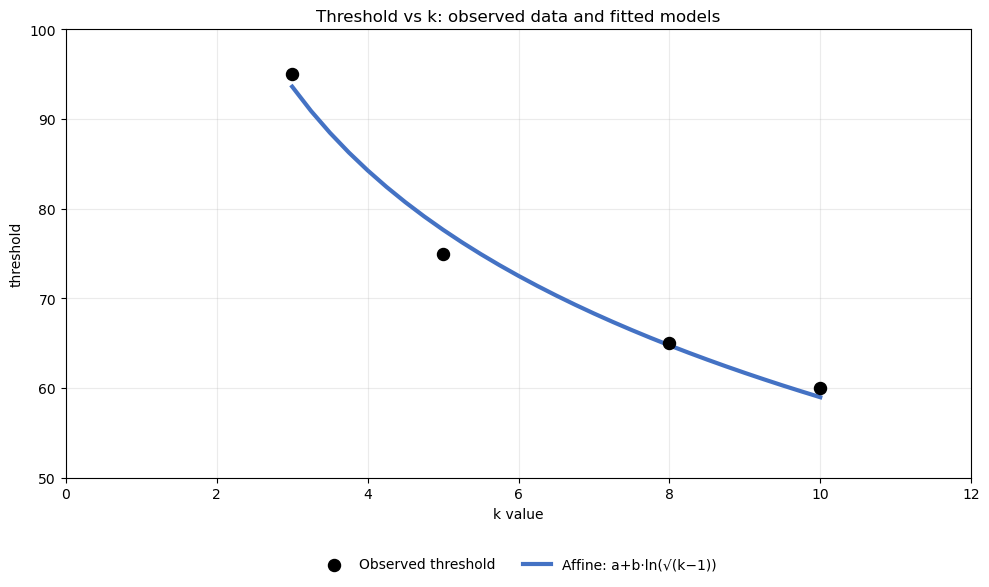

In [23]:
# %% [markdown]
# # Threshold model comparison
# This notebook reproduces the data, five fitted models, diagnostics, curve table, and chart from Excel.
 
# %% Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
 
# %% Observed data from Sheet1!A2:B5
observed = pd.DataFrame({
'k value': [10, 5, 8, 3],
'threshold': [60.0, 75.0, 65.0, 95.0],
})
k = observed['k value'].to_numpy(dtype=float)
y = observed['threshold'].to_numpy(dtype=float)
 
# %% Helper functions
def fit_through_origin(x, y):
    return np.dot(x, y) / np.dot(x, x)
 
def diagnostics(y, y_hat):
    sse = np.sum((y - y_hat) ** 2)
    r2 = 1 - sse / np.sum((y - y.mean()) ** 2)
    return sse, r2
 
# %% Transformations used by the Excel formulas
x_direct = np.sqrt(k - 1)
x_inverse = 1 / np.sqrt(k - 1)
x_log_sqrt = np.log(np.sqrt(k - 1))
x_log = np.log(k - 1)
 
# %% Fit the four proportional models (intercept fixed at zero)
a_direct = fit_through_origin(x_direct, y)
a_inverse = fit_through_origin(x_inverse, y)
a_log_sqrt = fit_through_origin(x_log_sqrt, y)
a_log = fit_through_origin(x_log, y)
 
# Fit y = intercept + slope * ln(sqrt(k - 1))
slope_affine, intercept_affine = np.polyfit(x_log_sqrt, y, 1)
 
models = {
# 'Direct: a√(k−1)': (0.0, a_direct, lambda z: a_direct * np.sqrt(z - 1)),
# 'Inverse: a/√(k−1)': (0.0, a_inverse, lambda z: a_inverse / np.sqrt(z - 1)),
# 'Proportional: a·ln(√(k−1))': (0.0, a_log_sqrt, lambda z: a_log_sqrt * np.log(np.sqrt(z - 1))),
# 'Proportional: a·ln(k−1)': (0.0, a_log, lambda z: a_log * np.log(z - 1)),
'Affine: a+b·ln(√(k−1))': (intercept_affine, slope_affine, lambda z: intercept_affine + slope_affine * np.log(np.sqrt(z - 1))),
}
 
# %% Model summary matching Sheet1!F1:J6
summary_rows = []
for name, (intercept, scale, predict) in models.items():
    sse, r2 = diagnostics(y, predict(k))
    summary_rows.append({
        'Model': name,
        'Intercept': intercept,
        'Scale / slope': scale,
        'SSE': sse,
        'R²': r2,
    })
    
model_summary = pd.DataFrame(summary_rows)
display(model_summary.style.format({
'Intercept': '{:.4f}',
'Scale / slope': '{:.4f}',
'SSE': '{:.2f}',
'R²': '{:.3f}',
}))
 
# %% Observed-point fitted values matching Sheet1!C:D and R:T
observed_fits = observed.copy()
for name, (_, _, predict) in models.items():
    observed_fits[name] = predict(k)
    display(observed_fits.style.format(precision=2))
 
# %% Curve grid matching Sheet1!K2:P30
    k_curve = np.arange(3.0, 10.0 + 0.25, 0.25)
    curve_data = pd.DataFrame({'k (curve)': k_curve})
for name, (_, _, predict) in models.items():
    curve_data[name] = predict(k_curve)
    display(curve_data.style.format(precision=2))
 
# %% Chart
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(k, y, s=75, color='black', label='Observed threshold', zorder=5)
colors = ['#4472C4', '#ED7D31', '#70AD47', '#A5A5A5', '#7030A0']
for (name, (_, _, predict)), color in zip(models.items(), colors):
    width = 3.0 if name.startswith('Affine') else 1.8
    ax.plot(k_curve, predict(k_curve), label=name, color=color, linewidth=width)

    ax.set_title('Threshold vs k: observed data and fitted models')
    ax.set_xlabel('k value')
    ax.set_ylabel('threshold')
    ax.set_xlim(0, 12)
    ax.set_ylim(50, 100)
    ax.grid(True, alpha=0.25)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)
    fig.tight_layout()
    plt.show()
 
# %% Optional: save notebook outputs
model_summary.to_csv('model_summary.csv', index=False)
curve_data.to_csv('threshold_model_curves.csv', index=False)
fig.savefig('threshold_model_comparison.png', dpi=150, bbox_inches='tight', facecolor='white')

          a (slope)  b (intercept)      R²
balanced    -34.415       109.2688  0.9312


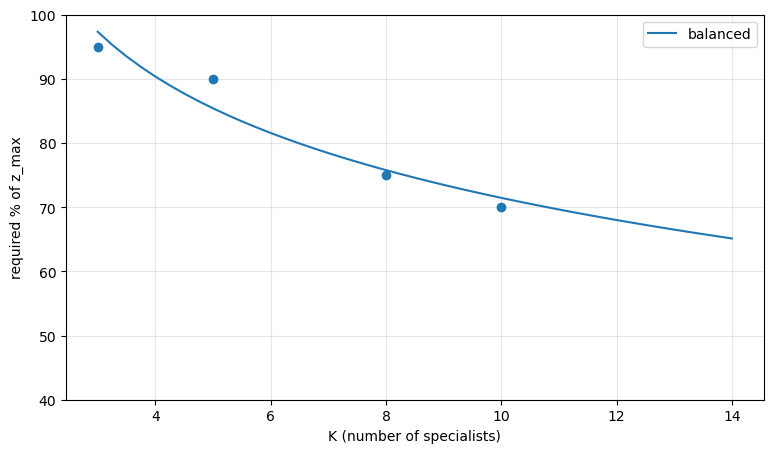

KeyError: 'specialist'

In [9]:
# %% Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# %% Fit p*(K) = a * ln(sqrt(K - 1)) + b
def fit_curve(ks, ps):
    x = np.log(np.sqrt(np.asarray(ks, float) - 1))
    y = np.asarray(ps, float)
    a, b = np.polyfit(x, y, 1)                          # a = slope, b = intercept
    r2 = 1 - np.sum((y - (a * x + b)) ** 2) / np.sum((y - y.mean()) ** 2)
    return a, b, r2

def curve(K, a, b):
    return a * np.log(np.sqrt(np.asarray(K, float) - 1)) + b

# %% Thresholds picked from the MMLU reranker calibration sweep
points = {
    "balanced":   ([3, 5, 8, 10], [95, 90, 75, 70]),   # spec recall ≈ gen recall
#     "specialist": ([3, 5, 8, 10], [95, 90, 60, 55]),   # highest p with spec recall ≥ 0.90
#     "general":    ([5, 8, 10],    [90, 80, 75]),       # lowest p with gen recall ≥ 0.90 (K=3 excluded)
}
fits = {name: fit_curve(ks, ps) for name, (ks, ps) in points.items()}
print(pd.DataFrame(fits, index=["a (slope)", "b (intercept)", "R²"]).T.round(4))

# %% Plot all three curves with their points
k_curve = np.arange(3, 14.25, 0.25)
fig, ax = plt.subplots(figsize=(9, 5))
for name, (a, b, _) in fits.items():
    line, = ax.plot(k_curve, curve(k_curve, a, b), label=name)
    ax.scatter(*points[name], color=line.get_color(), zorder=5)
ax.set(xlabel="K (number of specialists)", ylabel="required % of z_max", ylim=(40, 100))
ax.grid(alpha=0.3)
ax.legend()
plt.show()
fig.savefig("threshold_curves.png", dpi=150, bbox_inches="tight")

# %% Values to use in the router / MedMCQA table
a_bal, b_bal = fits["balanced"][:2]
a_spec, b_spec = fits["specialist"][:2]
a_gen, b_gen = fits["general"][:2]